# puntuación aprendida de acciones: Métodos y evidencia

**Nivel:** 1 **Requisitos previos:** 01-fast-event-control **Tiempo de lectura:** 15 minutos

**Pregunta:** ¿Qué evidencia distingue los puntajes candidatos M03 y M04 de un resultado C05 correcto y verificado independientemente?

## Objetivos

Esta lección investiga la pregunta: ¿Qué evidencia distingue los puntajes candidatos M03 y M04 de un resultado C05 correcto y verificado independientemente?

## Preparación

Las versiones siguientes están fijadas en `notebooks/requirements.txt` y también constan en los metadatos de este notebook; ```bash pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2 ```

In [1]:
# Importa la API publicada de políticas y las dependencias fijadas de gráficos y ejecución.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Datos
El notebook lee artefactos comprometidos del producto. Propietario: Neuraxis. Repositorio: https://github.com/fsantibanezleal/CAOS_Neuraxis. Licencia: Apache-2.0. El JSON es un artefacto experimental propio y congelado; este notebook no redistribuye datos de benchmarks externos;

Este notebook lee `data/derived/index.json` y las trazas listadas. La ejecución usa un espacio aislado de caso Reflexmesh; Para métodos aprendidos, descarga los activos públicos exactos con `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000` y define `NEURAXIS_CHECKPOINTS` hacia esa carpeta; El manifiesto de publicación verifica los hashes. M09/M10 se leen desde trazas congeladas, salvo que `NEURAXIS_NOTEBOOK_MODEL` indique explícitamente un modelo Ollama local configurado;

Artefactos de esta lección:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/episodes/M03-C05-nominal-40000; - `data/derived/episodes/M04-C05-nominal-40000; json`

## Método

Sigue las características candidatas desde un estado C05 observado hasta un puntuador ajustado. La lección separa la preferencia aprendida de la máscara de admisibilidad y del verificador independiente, para no confundir probabilidad, autoridad de acción y éxito de tarea.

### puntuación aprendida de acciones · nivel 1 | Verifica la auditoría y los bytes de cada traza antes de interpretar resultados.

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M03', 'M04']
sample_case, seed = 'C05', 40000
evidence = load_lesson_evidence(
    ROOT, topic='02-learned-action-policies', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=False,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))


Hash-verified records: 2 | case variants: 12


### Inspeccionar una traza con guardas: puntuación aprendida de acciones

C05 ofrece un conjunto concreto de opciones a las políticas de puntuación; verifica si la acción elegida satisface el evaluador.

Lee el conjunto de acciones admisibles antes de mirar la puntuación aprendida. El puntaje ordena preferencias entre acciones que el entorno ya expone; no amplía permisos ni agrega capacidades. Sigue la operación seleccionada hasta el verificador para distinguir un orden plausible de una tarea completada. Un episodio muestra la llamada y la carga del modelo, pero no demuestra generalización fuera del estado muestreado.

### puntuación aprendida de acciones · L1 | Construir la primera política ejecutable

Construye M01 para puntuación aprendida de acciones con la fábrica pública y conserva su contrato de observación antes de muestrear C05.

In [3]:
# Construye la primera política publicada mediante la fábrica pública.
primary_id = 'M03'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Política principal:", primary_id)


Política principal: M03


### puntuación aprendida de acciones · L1 | Ejecutar el método principal en el caso indicado

De puntuación aprendida de acciones, el evaluador ejecuta M01 en C05 y deriva el éxito de la poscondición independiente, no de una traza reproducida.

In [4]:
# Ejecuta la política y verifica independientemente la poscondición del caso.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea principal:", primary_result["metrics"]["task_success"])


Éxito de tarea principal: 1


### puntuación aprendida de acciones · L1 | Construir una política de comparación independiente

Crea M02 como objeto nuevo para impedir que el estado recurrente de M01 contamine la comparación

In [5]:
# Crea un objeto de política nuevo para la comparación emparejada.
secondary_id = 'M04'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Política de comparación:", secondary_id)


Política de comparación: M04


### puntuación aprendida de acciones · L1 | Ejecutar la comparación bajo condiciones idénticas

Esta comparación de nivel 1 ejecuta M02 en el mismo C05, variante nominal y semilla, y ilustra comportamiento, no estima una tasa poblacional.

In [6]:
# Usa el mismo caso, variante y semilla para la segunda política.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Éxito de tarea de comparación:", secondary_result["metrics"]["task_success"])


Éxito de tarea de comparación: 1


### puntuación aprendida de acciones · L1 | Agregar los dos episodios ejecutados

El agregador resume dos episodios ejecutados de puntuación aprendida de acciones, y las afirmaciones entre familias aún requieren el benchmark completo

In [7]:
# Agrega los resultados ejecutados con el evaluador descriptivo del paquete.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Ejecuciones nuevas de políticas:", len(fresh_runs))
print("Éxitos de las ejecuciones nuevas:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Ejecuciones nuevas de políticas: 2
Éxitos de las ejecuciones nuevas: 2


### puntuación aprendida de acciones · L1 | Resultados de políticas nuevas

El gráfico siguiente se calcula con los resultados de episodios de puntuación aprendida de acciones recién ejecutados en C05, no se copia de un artefacto congelado

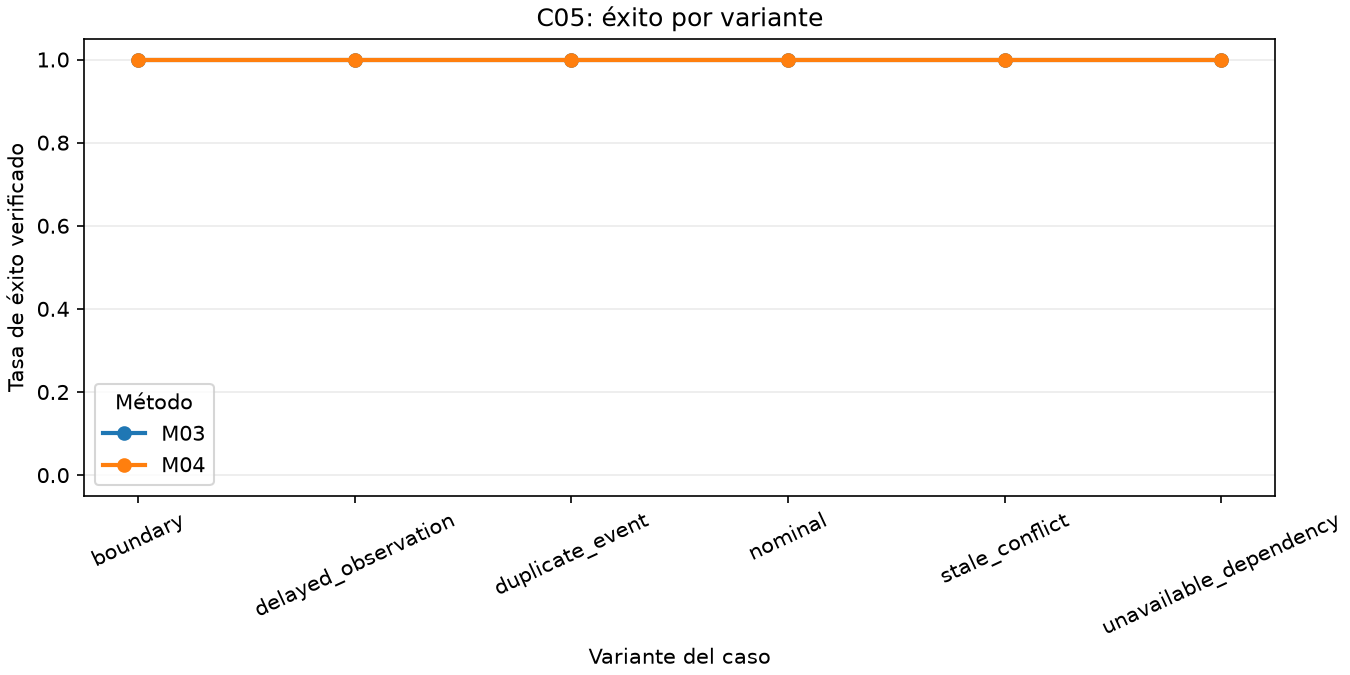

In [8]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Tasa de éxito verificado")
ax.set_xlabel("Variante del caso")
ax.set_title(sample_case + ": éxito por variante")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if True else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


Para puntuación aprendida de acciones, estas barras muestran resultados nuevos de poscondición de M01 y M02 en C05; Éxito vale 1 y falla 0. Lee el caso y la semilla antes de compararlas. En el ejercicio de una ejecución de puntuación aprendida de acciones para C05, este episodio controlado ilustra el comportamiento, pero no es un intervalo de confianza ni establece generalización a otras tareas de software;

## Resultados

**Respuesta:** El ejemplo de puntuación aprendida de acciones ejecuta 2 políticas, M03 y M04, en C05;

En el ejercicio de una ejecución de puntuación aprendida de acciones para C05, los checkpoints del paquete se publican como activos separados y no están versionados en este repositorio; En el ejercicio de una ejecución de puntuación aprendida de acciones para C05, los resultados de los métodos ajustados son evaluaciones registradas y verificadas por hash, no modelos reajustados ahora; En el ejemplo de puntuación aprendida de acciones con C05, una tasa en familias diseñadas no estima el rendimiento en tareas de software arbitrarias;

En el ejercicio de una ejecución de puntuación aprendida de acciones para C05, este paso de autoría no compromete salidas generadas;

## Resumen

C05 muestra cómo un puntaje elige entre acciones admisibles, no cómo se conceden permisos.




## Referencias
- [XGB](https://arxiv.org/abs/1603.02754) - [GRU](https://arxiv.org/abs/1406.1078) - [LINUCB](https://arxiv.org/abs/1003.0146)